## Learning banana with CNF

In [24]:
import math
import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import diffrax
import optax
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

jax.config.update("jax_enable_x64", True)

Target distribution (banana Gaussian)

In [25]:
B = 0.5

def sample_banana(key, n):
    x = jr.normal(key, (n, 2))
    y1 = x[:, 0]
    y2 = x[:, 1] + B * x[:, 0] ** 2 - B
    return jnp.stack([y1, y2], axis=1)

def log_banana_density(y):
    y1, y2 = y[0], y[1]
    x2 = y2 - B * y1 ** 2 + B
    return -0.5 * (y1 ** 2 + x2 ** 2) - jnp.log(2 * jnp.pi)

TRUE_MEAN_LL = float(-(1.0 + jnp.log(2 * jnp.pi)))
print(f"Oracle -H(p*) = {TRUE_MEAN_LL:.4f}")

Oracle -H(p*) = -2.8379


CNF setup

In [26]:
class ConcatSquash(eqx.Module):
    lin1: eqx.nn.Linear
    lin2: eqx.nn.Linear
    lin3: eqx.nn.Linear

    def __init__(self, in_size, out_size, *, key):
        k1, k2, k3 = jr.split(key, 3)
        self.lin1 = eqx.nn.Linear(in_size, out_size, key=k1)
        self.lin2 = eqx.nn.Linear(1, out_size, key=k2)
        self.lin3 = eqx.nn.Linear(1, out_size, use_bias=False, key=k3)

    def __call__(self, t, y):
        return (self.lin1(y) * jax.nn.sigmoid(self.lin2(t))
                + self.lin3(t))


# ── Vector field using ConcatSquash ──────────────────────────────
class Func(eqx.Module):
    layers: list

    def __init__(self, data_size, width_size, depth, *, key):
        keys = jr.split(key, depth + 1)
        layers = [ConcatSquash(data_size, width_size, key=keys[0])]
        for i in range(depth - 1):
            layers.append(ConcatSquash(width_size, width_size, key=keys[i+1]))
        layers.append(ConcatSquash(width_size, data_size, key=keys[-1]))
        self.layers = layers

    def __call__(self, t, y, args):
        t = jnp.asarray(t)[None]
        for layer in self.layers[:-1]:
            y = jax.nn.tanh(layer(t, y))
        return self.layers[-1](t, y)


# ── Exact log-density wrapper (Kidger's exact_logp_wrapper, i.e., augmented ODE) ──────
def exact_logp_wrapper(t, y, args):
    y, _ = y
    func = args
    fn = lambda y: func(t, y, None)
    f, vjp_fn = jax.vjp(fn, y)
    (size,) = y.shape
    eye = jnp.eye(size)
    (dfdy,) = jax.vmap(vjp_fn)(eye)
    logp = jnp.trace(dfdy)
    return f, logp

def normal_log_likelihood(y):
    return -0.5 * (y.size * math.log(2 * math.pi) + jnp.sum(y**2))


# ── Single log-likelihood (backward solve) ────────────────────────
def _single_log_likelihood(func, y):
    term = diffrax.ODETerm(exact_logp_wrapper)
    y0 = (y, 0.0)
    sol = diffrax.diffeqsolve(
        term, diffrax.Tsit5(),
        t0=1.0, t1=0.0, dt0=-0.05,   # t0 > t1, dt0 negative = backward
        y0=y0, args=func,
        saveat=diffrax.SaveAt(t1=True),
        stepsize_controller=diffrax.PIDController(rtol=1e-5, atol=1e-5),
    )
    y_out   = sol.ys[0][0]
    delta_logp = sol.ys[1][0]
    return normal_log_likelihood(y_out) + delta_logp

@eqx.filter_jit
def batch_log_likelihood(func, ys):
    return jax.vmap(lambda y: _single_log_likelihood(func, y))(ys)

Training setup

In [27]:
def train_cnf(n_train, key, *, width=32, depth=2, lr=1e-3,
              weight_decay=1e-5):
    n_steps = {100: 400, 200: 600, 500: 1000, 1000: 1500, 2000: 2500}.get(n_train, 1000)
    batch_size = min(256, n_train)

    key, k_data, k_model = jr.split(key, 3)
    data = sample_banana(k_data, n_train)
    std  = jnp.std(data, axis=0) + 1e-6   # for noise scaling

    func = Func(data_size=2, width_size=width, depth=depth, key=k_model)

    optim     = optax.adamw(lr, weight_decay=weight_decay)
    opt_state = optim.init(eqx.filter(func, eqx.is_inexact_array))

    @eqx.filter_jit
    def make_step(func, opt_state, batch, noise_key):
        # ── Kidger's data noise: prevents density collapse ──
        batch = batch + jr.normal(noise_key, batch.shape) * 0.05 / std

        def loss_fn(f):
            lls = jax.vmap(lambda y: _single_log_likelihood(f, y))(batch)
            return -jnp.mean(lls)

        loss_val, grads = eqx.filter_value_and_grad(loss_fn)(func)
        updates, new_opt_state = optim.update(
            grads, opt_state, eqx.filter(func, eqx.is_inexact_array)
        )
        return eqx.apply_updates(func, updates), new_opt_state, loss_val

    for step in range(n_steps):
        key, k_batch, k_noise = jr.split(key, 3)
        idx   = jr.randint(k_batch, (batch_size,), 0, n_train)
        batch = data[idx]
        func, opt_state, loss = make_step(func, opt_state, batch, k_noise)
        if (step + 1) % 100 == 0:
            print(f"  step {step+1:4d}  loss = {loss:.4f}")

    return func

Statistical analysis setup

In [28]:
def compute_test_stats(func, key, M):
    test_data = sample_banana(key, M)
    lls = np.array(batch_log_likelihood(func, test_data))
    return float(lls.mean()), float(lls.std(ddof=1))

def aci_95(mean_ll, std_ll, M):
    z  = stats.norm.ppf(0.975)
    hw = z * std_ll / np.sqrt(M)
    return mean_ll - hw, mean_ll + hw

Large sample behavior of trained CNF via asymptotic confidence intervals


Training n = 100 …
  step  100  loss = 2.9191
  step  200  loss = 2.9073
  step  300  loss = 2.5899
  step  400  loss = 2.7255
  mean LL = -3.0066,  95% ACI = [-3.0745, -2.9388],  oracle inside = False

Training n = 200 …
  step  100  loss = 3.0878
  step  200  loss = 2.9530
  step  300  loss = 2.9490
  step  400  loss = 2.9000
  step  500  loss = 2.8911
  step  600  loss = 2.7264
  mean LL = -2.9169,  95% ACI = [-2.9637, -2.8700],  oracle inside = False

Training n = 500 …
  step  100  loss = 3.0564
  step  200  loss = 3.0360
  step  300  loss = 3.0466
  step  400  loss = 2.9700
  step  500  loss = 2.8965
  step  600  loss = 2.8587
  step  700  loss = 2.8576
  step  800  loss = 2.8927
  step  900  loss = 3.0415
  step 1000  loss = 2.8646
  mean LL = -2.8859,  95% ACI = [-2.9286, -2.8432],  oracle inside = False

Training n = 1000 …
  step  100  loss = 2.9211
  step  200  loss = 2.8831
  step  300  loss = 2.8531
  step  400  loss = 2.7620
  step  500  loss = 2.8402
  step  600  loss =

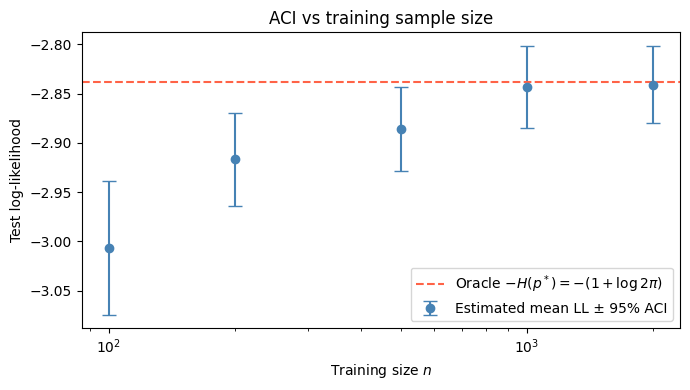

In [29]:
training_sizes = [100, 200, 500, 1000, 2000]
M_TEST     = 2500
master_key = jr.PRNGKey(1)
master_key, k_test = jr.split(master_key)
test_data = sample_banana(k_test, M_TEST)
results_A = {}

trained_models = {}

for n in training_sizes:
    master_key, k_train, k_test = jr.split(master_key, 3)
    print(f"\nTraining n = {n} …")
    func = train_cnf(n, k_train)
    trained_models[n] = func

    mu, sigma = compute_test_stats(func, k_test, M_TEST)
    lo, hi    = aci_95(mu, sigma, M_TEST)
    results_A[n] = dict(mean=mu, lo=lo, hi=hi, contains=(lo <= TRUE_MEAN_LL <= hi))
    print(f"  mean LL = {mu:.4f},  95% ACI = [{lo:.4f}, {hi:.4f}],  "
          f"oracle inside = {results_A[n]['contains']}")


# plotting
ns    = list(results_A.keys())
means = [results_A[n]['mean'] for n in ns]
los   = [results_A[n]['lo']   for n in ns]
his   = [results_A[n]['hi']   for n in ns]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(ns, means,
            yerr=[np.array(means)-np.array(los), np.array(his)-np.array(means)],
            fmt='o', capsize=5, color='steelblue',
            label='Estimated mean LL ± 95% ACI')
ax.axhline(TRUE_MEAN_LL, color='tomato', linestyle='--',
           label=r'Oracle $-H(p^*) = -(1+\log 2\pi)$')
ax.set_xscale('log')
ax.set_xlabel('Training size $n$')
ax.set_ylabel('Test log-likelihood')
ax.set_title('ACI vs training sample size')
ax.legend(); plt.tight_layout()
plt.savefig('CNF_ACI.pdf'); plt.show()

Density comparisons (truth vs learned)

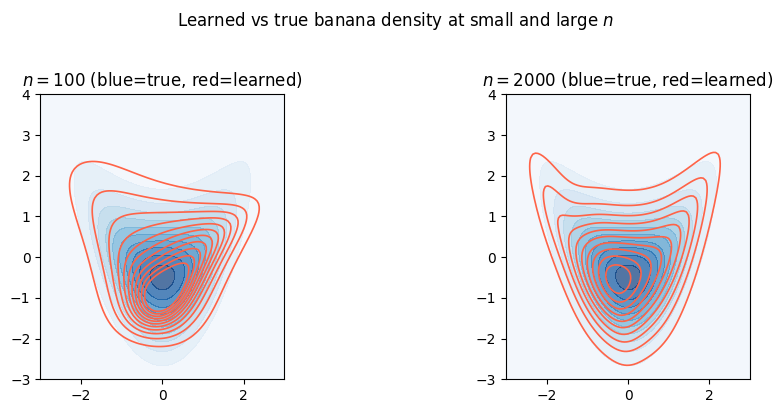

In [30]:
def plot_density_comparison(func, n_label, ax):
    grid_x = np.linspace(-3, 3, 100)
    grid_y = np.linspace(-3, 4, 100)
    XX, YY = np.meshgrid(grid_x, grid_y)
    grid   = jnp.array(np.stack([XX.ravel(), YY.ravel()], axis=1))

    p_true  = np.array(jnp.exp(jax.vmap(log_banana_density)(grid))).reshape(100, 100)
    p_model = np.exp(np.array(batch_log_likelihood(func, grid))).reshape(100, 100)

    # Shared levels based on true density range
    levels = np.linspace(0, p_true.max() * 1.05, 12)

    ax.contourf(XX, YY, p_true,  levels=levels, cmap='Blues', alpha=0.7)
    ax.contour( XX, YY, p_model, levels=levels, colors='tomato', linewidths=1.2)
    ax.set_title(f'$n={n_label}$ (blue=true, red=learned)')
    ax.set_aspect('equal')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for n_plot, ax in zip([100, 2000], axes):
    plot_density_comparison(trained_models[n_plot], n_plot, ax)

fig.suptitle('Learned vs true banana density at small and large $n$', y=1.02)
plt.tight_layout()
plt.savefig('density_comparison.pdf', bbox_inches='tight')
plt.show()